# Machine Learning Midterm — breast_cancer
All numbered sections follow the assignment. All experiments use fixed test indices and three train/validation seeds.

In [1]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sklearn, sys
from pathlib import Path
from sklearn.datasets import load_breast_cancer,load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,roc_curve,auc,adjusted_rand_score,silhouette_score
from sklearn.preprocessing import label_binarize
from sklearn.impute import SimpleImputer
from IPython.display import display
SEEDS=[42,52,62]; ROOT=Path('.'); FIG=ROOT/'figures';FIG.mkdir(exist_ok=True)
print('Versions:',sys.version.split()[0], 'sklearn',sklearn.__version__,'pandas',pd.__version__,'numpy',np.__version__)
def savefig(name):
 plt.tight_layout();plt.savefig(FIG/name,dpi=125,bbox_inches='tight');plt.show();plt.close()
def scores(model,X,y,dataset):
 pred=model.predict(X); prob=model.predict_proba(X)
 classes=model.classes_
 if dataset=='breast_cancer':
  roc=roc_auc_score((np.asarray(y)==0).astype(int),prob[:,list(classes).index(0)])
 else: roc=roc_auc_score(y,prob,labels=classes,multi_class='ovr',average='macro')
 return dict(accuracy=accuracy_score(y,pred),precision=precision_score(y,pred,average='macro',zero_division=0),recall=recall_score(y,pred,average='macro',zero_division=0),f1=f1_score(y,pred,average='macro',zero_division=0),auc=roc)
def make_model(algo,param,seed):
 if algo=='tree':return DecisionTreeClassifier(max_depth=param,random_state=seed)
 if algo=='knn':return KNeighborsClassifier(n_neighbors=param,weights='uniform',metric='euclidean')
 return GaussianNB()
def sil(X,labels):
 n=len(np.unique(labels))
 return silhouette_score(X,labels) if 1<n<len(labels) else np.nan


Versions: 3.11.4 sklearn 1.8.0 pandas 2.2.3 numpy 2.3.5


## 1. Loading the Datasets

In [2]:
dataset='breast_cancer'
bunch=load_breast_cancer() if dataset=='breast_cancer' else load_wine()
X=pd.DataFrame(bunch.data,columns=bunch.feature_names);y=pd.Series(bunch.target,index=X.index,name='target')
print('Shape:',X.shape,'Labels:',sorted(y.unique()),'Names:',list(bunch.target_names));print('Class counts:',y.value_counts().sort_index().to_dict());print('Features:',list(X.columns));display(X.head())
print('Interpretation: Features and original target labels are separate. Breast cancer class 0 means malignant and class 1 benign.' if dataset=='breast_cancer' else 'Interpretation: Wine retains its original classes 0, 1 and 2.')

Shape: (569, 30) Labels: [np.int64(0), np.int64(1)] Names: [np.str_('malignant'), np.str_('benign')]
Class counts: {0: 212, 1: 357}
Features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Interpretation: Features and original target labels are separate. Breast cancer class 0 means malignant and class 1 benign.


## 2. Dataset Quality Checks

In [3]:
print('Missing per column:');display(X.isna().sum().to_frame('missing'));print('Duplicate feature rows:',X.duplicated().sum());display(X.dtypes.to_frame('dtype'));print('Numerical:',X.select_dtypes(include='number').shape[1],'Categorical:',X.select_dtypes(exclude='number').shape[1]);q1=X.quantile(.25);q3=X.quantile(.75);iqr=q3-q1;out=((X.lt(q1-1.5*iqr))|(X.gt(q3+1.5*iqr))).sum();display(out.to_frame('IQR potential outliers'));print('Interpretation: IQR flags extreme observations, not necessarily errors; no rows are deleted. Extremes may affect distances, scaling and fitted boundaries.')

Missing per column:


,missing
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Duplicate feature rows: 0


,dtype
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64
mean compactness,float64
mean concavity,float64
mean concave points,float64
mean symmetry,float64
mean fractal dimension,float64


Numerical: 30 Categorical: 0


,IQR potential outliers
mean radius,14
mean texture,7
mean perimeter,13
mean area,25
mean smoothness,6
mean compactness,16
mean concavity,18
mean concave points,10
mean symmetry,15
mean fractal dimension,15


Interpretation: IQR flags extreme observations, not necessarily errors; no rows are deleted. Extremes may affect distances, scaling and fitted boundaries.


## 3. Exploratory Data Analysis (EDA)

,mean,median,min,max,std,Q1,Q3
mean radius,14.127292,13.370000,6.981000,28.11000,3.524049,11.700000,15.780000
mean texture,19.289649,18.840000,9.710000,39.28000,4.301036,16.170000,21.800000
mean perimeter,91.969033,86.240000,43.790000,188.50000,24.298981,75.170000,104.100000
mean area,654.889104,551.100000,143.500000,2501.00000,351.914129,420.300000,782.700000
mean smoothness,0.096360,0.095870,0.052630,0.16340,0.014064,0.086370,0.105300
mean compactness,0.104341,0.092630,0.019380,0.34540,0.052813,0.064920,0.130400
mean concavity,0.088799,0.061540,0.000000,0.42680,0.079720,0.029560,0.130700
mean concave points,0.048919,0.033500,0.000000,0.20120,0.038803,0.020310,0.074000
mean symmetry,0.181162,0.179200,0.106000,0.30400,0.027414,0.161900,0.195700
mean fractal dimension,0.062798,0.061540,0.049960,0.09744,0.007060,0.057700,0.066120


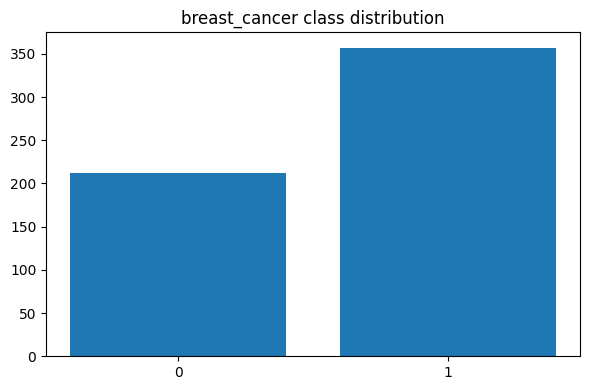

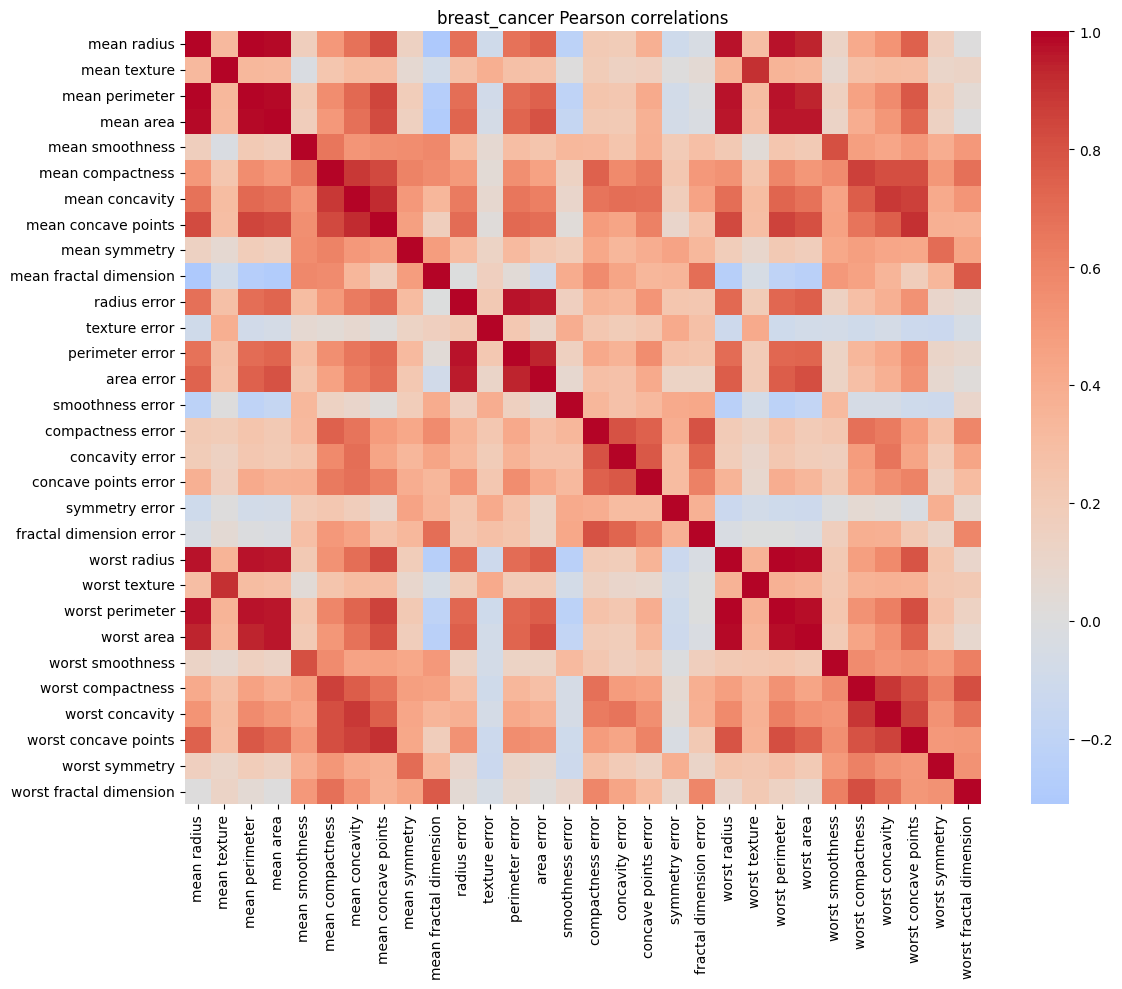

Top three unique absolute correlation pairs:


mean radius   mean perimeter     0.997855
worst radius  worst perimeter    0.993708
mean radius   mean area          0.987357
dtype: float64

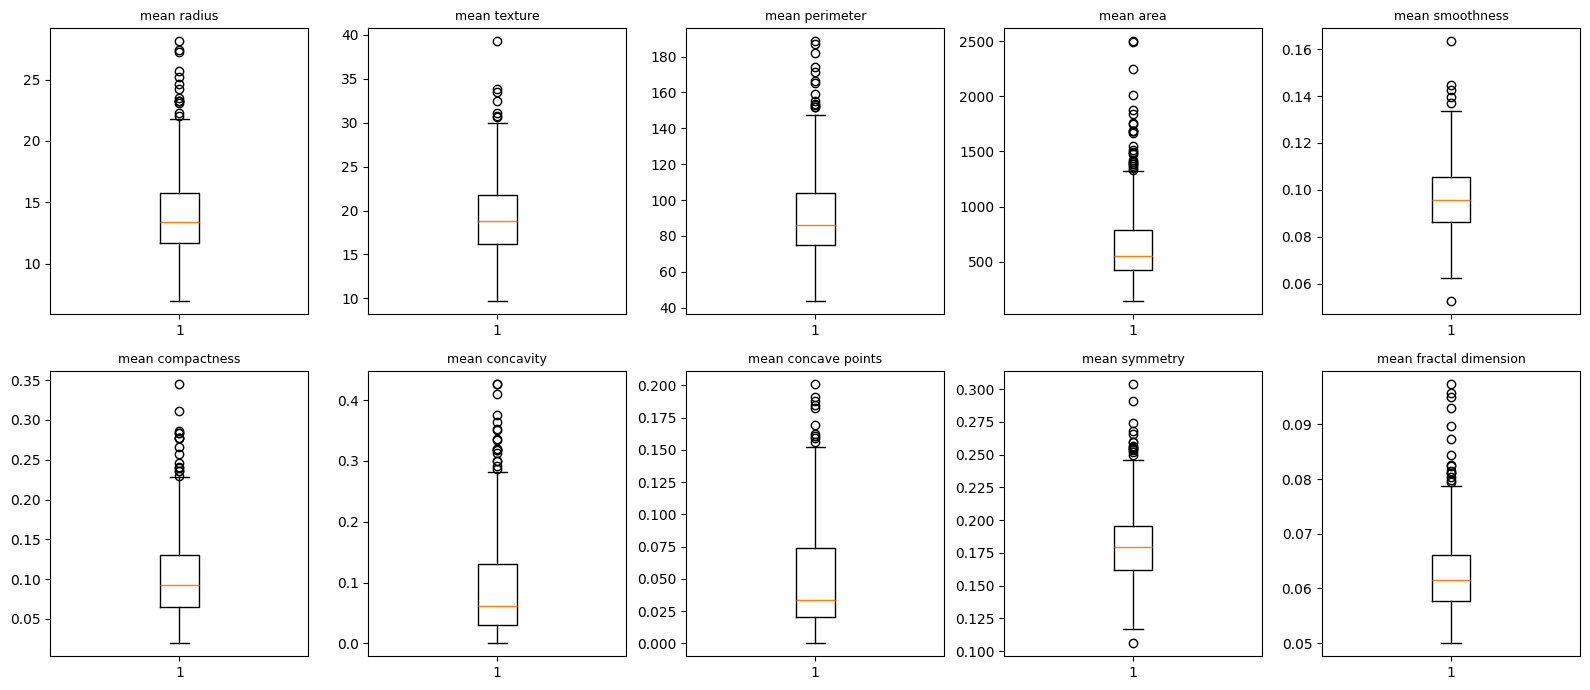

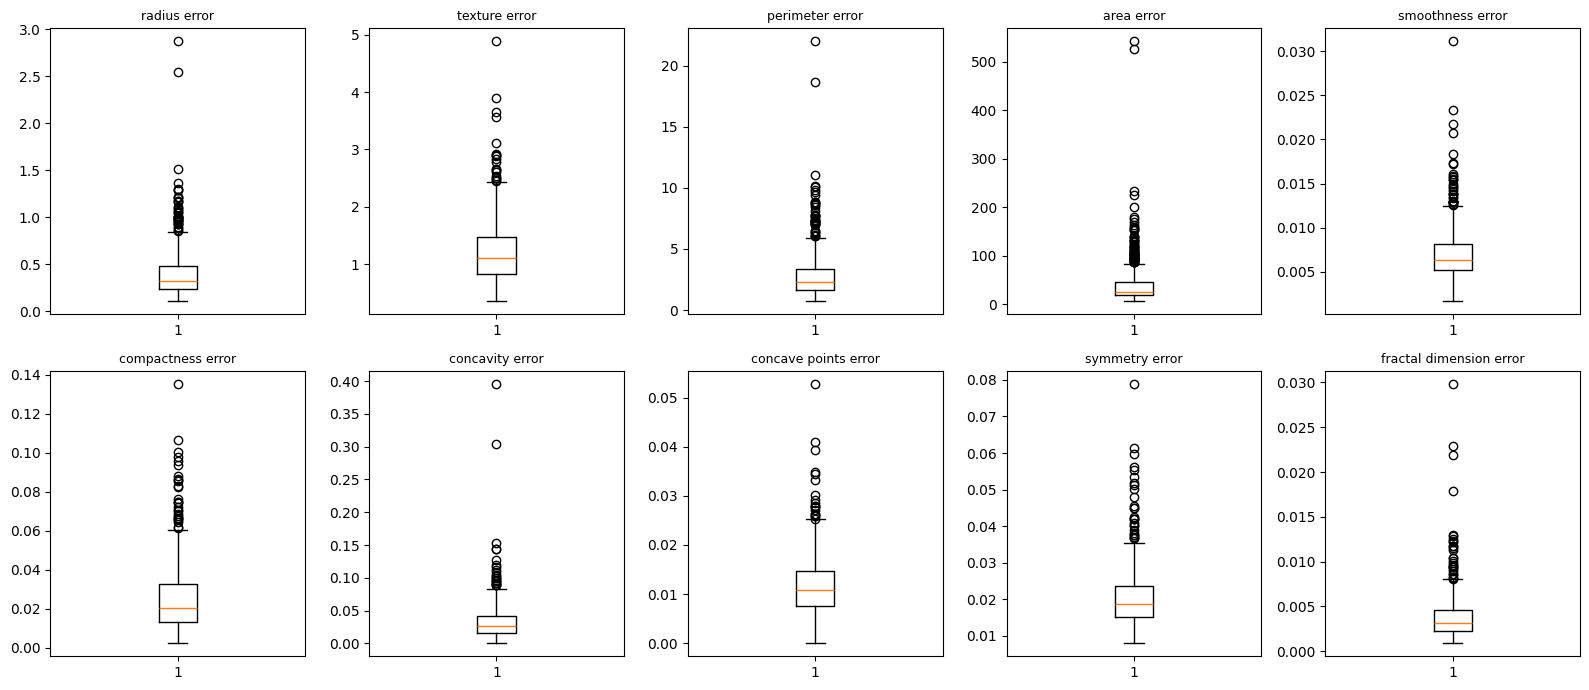

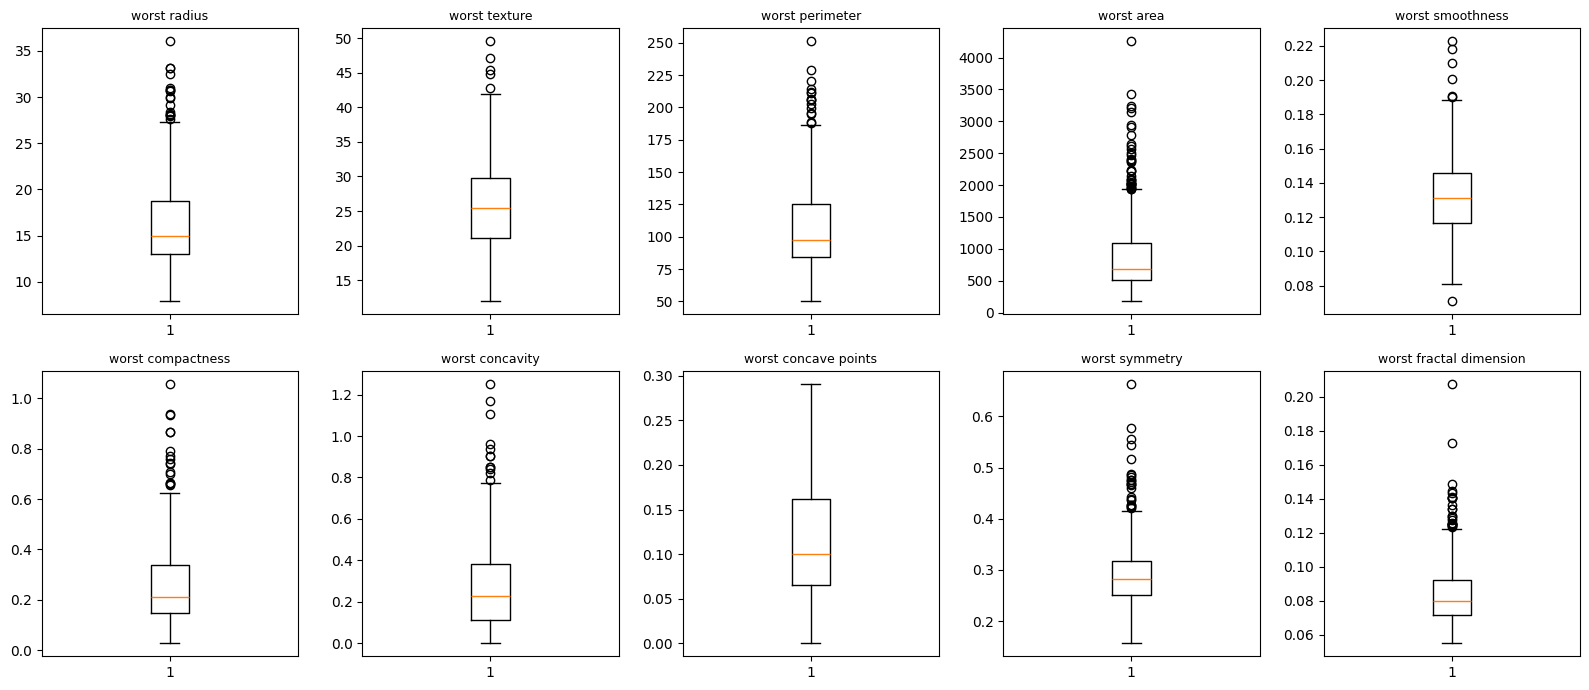

Interpretation: Feature ranges differ substantially, and boxplots flag possible outliers. Large-scale features can dominate Euclidean distances. EDA is descriptive and does not guide feature selection.


In [4]:
desc=X.describe().T[['mean','50%','min','max','std','25%','75%']].rename(columns={'50%':'median','25%':'Q1','75%':'Q3'});display(desc)
fig,ax=plt.subplots(figsize=(6,4));ax.bar(y.value_counts().sort_index().index.astype(str),y.value_counts().sort_index().values);ax.set_title(dataset+' class distribution');savefig(dataset+'_class_distribution.png')
corr=X.corr();fig,ax=plt.subplots(figsize=(12,10));sns.heatmap(corr,ax=ax,cmap='coolwarm',center=0);ax.set_title(dataset+' Pearson correlations');savefig(dataset+'_correlations.png')
upper=corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack();top=upper.reindex(upper.abs().sort_values(ascending=False).index).head(3);print('Top three unique absolute correlation pairs:');display(top)
for i in range(0,X.shape[1],10):
 cols=X.columns[i:i+10];fig,axes=plt.subplots(2,5,figsize=(16,7));
 for ax,col in zip(axes.flat,cols):ax.boxplot(X[col].to_numpy());ax.set_title(col,fontsize=9)
 for ax in list(axes.flat)[len(cols):]:ax.axis('off')
 savefig(f'{dataset}_boxplots_{i//10+1}.png')
print('Interpretation: Feature ranges differ substantially, and boxplots flag possible outliers. Large-scale features can dominate Euclidean distances. EDA is descriptive and does not guide feature selection.')

## 4. Splitting the Datasets

In [5]:
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
splits={};split_rows=[]
for seed in SEEDS:
 a,b,ya,yb=train_test_split(X_dev,y_dev,test_size=.125,stratify=y_dev,random_state=seed)
 splits[seed]=dict(X_train=a,X_val=b,y_train=ya,y_val=yb,X_test=X_test,y_test=y_test)
 assert not(set(a.index)&set(b.index) or set(a.index)&set(X_test.index) or set(b.index)&set(X_test.index))
 assert len(a)+len(b)+len(X_test)==len(X)
 for name,xx,yy in [('train',a,ya),('validation',b,yb),('test',X_test,y_test)]:split_rows.append(dict(seed=seed,subset=name,count=len(xx),percent=100*len(xx)/len(X),class_counts=str(yy.value_counts().sort_index().to_dict())))
display(pd.DataFrame(split_rows));print('Fixed test indices:',list(X_test.index));print('Training and validation indices per seed:')
for seed,s in splits.items():print(seed,'train',list(s['X_train'].index),'validation',list(s['X_val'].index))
assert all(s['X_test'].index.equals(X_test.index) for s in splits.values())
print('Interpretation: The test set is identical for all seeds; only train/validation membership changes.')

,seed,subset,count,percent,class_counts
0,42,train,398,69.947276,"{0: 149, 1: 249}"
1,42,validation,57,10.017575,"{0: 21, 1: 36}"
2,42,test,114,20.035149,"{0: 42, 1: 72}"
3,52,train,398,69.947276,"{0: 149, 1: 249}"
4,52,validation,57,10.017575,"{0: 21, 1: 36}"
5,52,test,114,20.035149,"{0: 42, 1: 72}"
6,62,train,398,69.947276,"{0: 149, 1: 249}"
7,62,validation,57,10.017575,"{0: 21, 1: 36}"
8,62,test,114,20.035149,"{0: 42, 1: 72}"


Fixed test indices: [256, 428, 501, 363, 564, 464, 358, 343, 516, 567, 292, 199, 527, 121, 353, 495, 541, 537, 308, 242, 223, 261, 467, 288, 549, 406, 23, 415, 266, 359, 247, 354, 452, 528, 85, 41, 310, 275, 526, 433, 217, 158, 267, 417, 64, 340, 307, 206, 375, 408, 284, 542, 507, 73, 150, 431, 316, 167, 168, 445, 399, 553, 295, 235, 77, 385, 291, 20, 518, 496, 231, 361, 140, 468, 328, 237, 194, 439, 269, 434, 204, 104, 70, 540, 205, 51, 483, 568, 200, 523, 423, 519, 535, 321, 83, 296, 1, 344, 203, 298, 127, 24, 14, 102, 180, 461, 246, 198, 504, 95, 128, 257, 228, 488]
Training and validation indices per seed:
42 train [301, 390, 420, 356, 446, 56, 82, 221, 339, 364, 37, 263, 341, 210, 514, 234, 99, 533, 482, 69, 484, 192, 392, 81, 245, 529, 91, 35, 456, 351, 79, 272, 270, 177, 469, 46, 163, 181, 107, 108, 332, 48, 262, 362, 379, 531, 146, 382, 562, 325, 98, 377, 400, 532, 539, 500, 100, 438, 460, 274, 419, 207, 441, 172, 411, 315, 347, 144, 306, 148, 233, 57, 36, 372, 409, 282, 287, 4

## 5. Data Preprocessing and Scaling

In [6]:
prepared={};has_missing=X.isna().any().any()
for seed,s in splits.items():
 train=s['X_train'].copy();val=s['X_val'].copy();test=s['X_test'].copy()
 imputer=None
 if has_missing:
  imputer=SimpleImputer(strategy='median');train=pd.DataFrame(imputer.fit_transform(train),columns=X.columns,index=train.index);val=pd.DataFrame(imputer.transform(val),columns=X.columns,index=val.index);test=pd.DataFrame(imputer.transform(test),columns=X.columns,index=test.index)
 scaler=StandardScaler();scaled_train=pd.DataFrame(scaler.fit_transform(train),columns=X.columns,index=train.index);scaled_val=pd.DataFrame(scaler.transform(val),columns=X.columns,index=val.index);scaled_test=pd.DataFrame(scaler.transform(test),columns=X.columns,index=test.index)
 prepared[seed]={'unscaled':(train,val,test),'scaled':(scaled_train,scaled_val,scaled_test),'scaler':scaler,'imputer':imputer}
print('Missing data:',has_missing,'; six independent scalers across two notebooks, one per dataset/seed.')
display(prepared[42]['unscaled'][0].head());display(prepared[42]['scaled'][0].head())
print('Interpretation: StandardScaler centers training columns and divides by training standard deviations; validation and test reuse these training-fitted parameters.')

Missing data: False ; six independent scalers across two notebooks, one per dataset/seed.


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
446,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420


Interpretation: StandardScaler centers training columns and divides by training standard deviations; validation and test reuse these training-fitted parameters.


## 6. Preparing the Two Data Representations

In [7]:
print('Both original and StandardScaler-transformed features retained for each seed, with identical indices.');assert all(prepared[s]['unscaled'][0].index.equals(prepared[s]['scaled'][0].index) for s in SEEDS)

Both original and StandardScaler-transformed features retained for each seed, with identical indices.


## 7. Training the Classification Models

## 8. Measuring Validation Performance

### Classifier Configuration Comparison

This section compares classifier configurations using validation results from three random seeds. Models are ranked primarily by mean validation macro-F1. The held-out test set is not used for model selection.

,dataset,run_id,configuration_id,seed,algorithm,representation,parameter,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_auc
0,breast_cancer,breast_cancer_tree_unscaled_2_s42,breast_cancer_tree_unscaled_2,42,tree,unscaled,2,0.954774,0.951595,0.894737,0.894737,0.876984,0.884459,0.875661
1,breast_cancer,breast_cancer_tree_unscaled_3_s42,breast_cancer_tree_unscaled_3,42,tree,unscaled,3,0.972362,0.970031,0.894737,0.894737,0.876984,0.884459,0.919312
2,breast_cancer,breast_cancer_tree_unscaled_5_s42,breast_cancer_tree_unscaled_5,42,tree,unscaled,5,0.997487,0.997314,0.912281,0.909459,0.900794,0.904778,0.921296
3,breast_cancer,breast_cancer_tree_unscaled_10_s42,breast_cancer_tree_unscaled_10,42,tree,unscaled,10,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
4,breast_cancer,breast_cancer_tree_unscaled_none_s42,breast_cancer_tree_unscaled_none,42,tree,unscaled,None,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,breast_cancer,breast_cancer_knn_scaled_3_s62,breast_cancer_knn_scaled_3,62,knn,scaled,3,0.984925,0.983820,0.982456,0.986486,0.976190,0.980956,0.997354
62,breast_cancer,breast_cancer_knn_scaled_5_s62,breast_cancer_knn_scaled_5,62,knn,scaled,5,0.972362,0.970294,0.982456,0.986486,0.976190,0.980956,0.999339
63,breast_cancer,breast_cancer_knn_scaled_7_s62,breast_cancer_knn_scaled_7,62,knn,scaled,7,0.969849,0.967453,1.000000,1.000000,1.000000,1.000000,1.000000
64,breast_cancer,breast_cancer_knn_scaled_11_s62,breast_cancer_knn_scaled_11,62,knn,scaled,11,0.972362,0.970209,1.000000,1.000000,1.000000,1.000000,1.000000


,dataset,configuration_id,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_f1_mean,train_f1_std,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_f1_mean,val_f1_std,val_auc_mean,val_auc_std
0,breast_cancer,breast_cancer_knn_scaled_7,knn,scaled,7,0.972362,0.002513,0.970234,0.002752,0.970760,0.026799,0.978408,0.019661,0.960317,0.036370,0.967675,0.029718,0.978175,0.019384
1,breast_cancer,breast_cancer_knn_scaled_11,knn,scaled,11,0.971524,0.001451,0.969381,0.001509,0.964912,0.035088,0.974561,0.025012,0.952381,0.047619,0.960846,0.039478,0.994489,0.004785
2,breast_cancer,breast_cancer_knn_scaled_3,knn,scaled,3,0.980737,0.003838,0.979314,0.004134,0.959064,0.020258,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979277,0.016151
3,breast_cancer,breast_cancer_knn_scaled_5,knn,scaled,5,0.974037,0.002901,0.972117,0.003158,0.959064,0.020258,0.969854,0.014404,0.944444,0.027493,0.954677,0.022757,0.979497,0.017386
4,breast_cancer,breast_cancer_knn_scaled_1,knn,scaled,1,1.000000,0.000000,1.000000,0.000000,0.941520,0.020258,0.940964,0.028337,0.933862,0.016038,0.936898,0.021295,0.933862,0.016038
5,breast_cancer,breast_cancer_gnb_unscaled_default,gnb,unscaled,default,0.937186,0.004352,0.932282,0.004872,0.941520,0.020258,0.938445,0.016375,0.937169,0.030759,0.936854,0.022646,0.979718,0.012572
6,breast_cancer,breast_cancer_gnb_scaled_default,gnb,scaled,default,0.935511,0.005230,0.930676,0.005764,0.929825,0.017544,0.923854,0.014035,0.927910,0.028912,0.924770,0.020075,0.975970,0.014941
7,breast_cancer,breast_cancer_tree_scaled_10,tree,scaled,10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
8,breast_cancer,breast_cancer_tree_scaled_none,tree,scaled,None,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
9,breast_cancer,breast_cancer_tree_unscaled_10,tree,unscaled,10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952


SELECTED FROM VALIDATION: breast_cancer_knn_scaled_7
Interpretation: Ranking uses mean validation macro-F1, then mean accuracy, lower sample F1 SD, then alphabetical ID. Test data are not used.


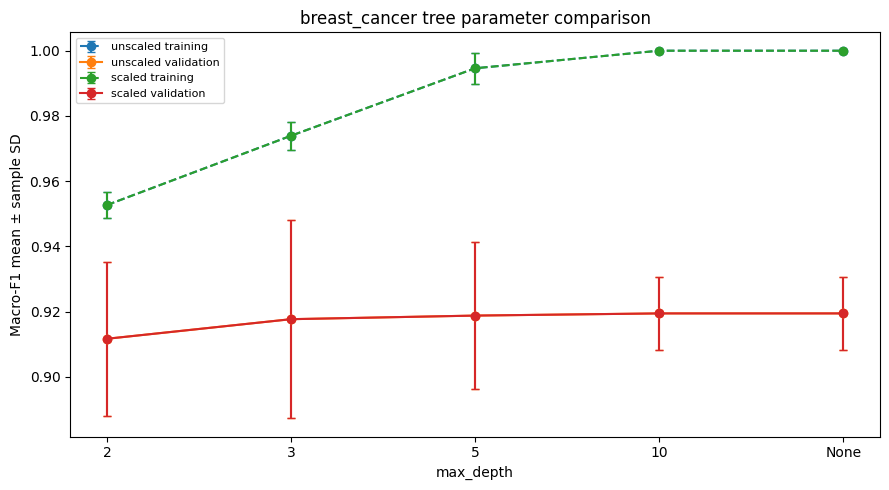

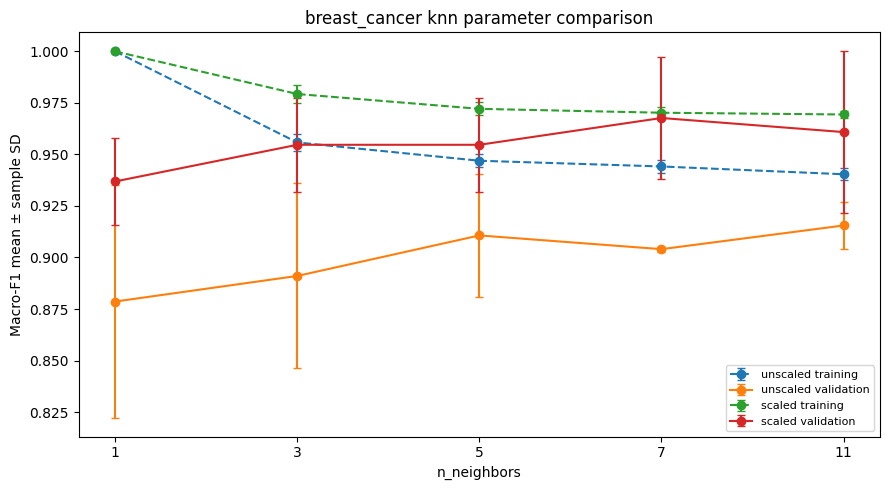

Interpretation: For the Breast Cancer dataset, the selected configuration is KNN with k=7 using scaled features. Its mean validation macro-F1 across three seeds is approximately 0.9677, with a sample standard deviation of 0.0297. The training and validation curves help compare model complexity and possible overfitting. The error bars represent variability across three overlapping train-validation splits, not independent test experiments.


In [8]:
configs=[('tree',d) for d in [2,3,5,10,None]]+[('knn',k) for k in [1,3,5,7,11]]+[('gnb','default')]
runs=[];fitted={}
for seed in SEEDS:
 for representation in ['unscaled','scaled']:
  a,b,_=prepared[seed][representation];ya=splits[seed]['y_train'];yb=splits[seed]['y_val']
  for algo,param in configs:
   cfg=f'{dataset}_{algo}_{representation}_{str(param).lower()}'
   model=make_model(algo,param,seed);model.fit(a,ya)
   if seed==42:fitted[(algo,representation,str(param))]=model
   tr=scores(model,a,ya,dataset);va=scores(model,b,yb,dataset)
   for c in np.unique(yb):
    actual=(yb==c).sum();pred=(model.predict(b)==c).sum();tp=((yb==c)&(model.predict(b)==c)).sum()
    if pred==0 or (actual>0 and tp==0 and pred==0):print('Undefined class precision before zero_division replacement:',cfg,seed,c)
   runs.append(dict(dataset=dataset,run_id=cfg+'_s'+str(seed),configuration_id=cfg,seed=seed,algorithm=algo,representation=representation,parameter=str(param),train_accuracy=tr['accuracy'],train_f1=tr['f1'],**{'val_'+k:v for k,v in va.items()}))
run_df=pd.DataFrame(runs);assert len(run_df)==66;display(run_df)
metrics=['train_accuracy','train_f1','val_accuracy','val_precision','val_recall','val_f1','val_auc']
summary=run_df.groupby(['dataset','configuration_id','algorithm','representation','parameter'],as_index=False)[metrics].agg(['mean','std']);summary.columns=['_'.join(filter(None,map(str,c))) for c in summary.columns.to_flat_index()];summary=summary.rename(columns={c:c[:-1] for c in summary.columns if c.endswith('_')});assert len(summary)==22
summary=summary.sort_values(['val_f1_mean','val_accuracy_mean','val_f1_std','configuration_id'],ascending=[False,False,True,True]).reset_index(drop=True)
display(summary);winner=summary.iloc[0];print('SELECTED FROM VALIDATION:',winner['configuration_id']);print('Interpretation: Ranking uses mean validation macro-F1, then mean accuracy, lower sample F1 SD, then alphabetical ID. Test data are not used.')
run_df['parameter'] = run_df['parameter'].fillna('None')
summary['parameter'] = summary['parameter'].fillna('None')
run_df.to_csv(ROOT/(dataset+'_classifier_runs.csv'),index=False,na_rep='None')
summary.to_csv(ROOT/(dataset+'_classifier_summary.csv'),index=False,na_rep='None')
for algo,params,filename,xlabel in [('tree',[2,3,5,10,None],'tree_depth','max_depth'),('knn',[1,3,5,7,11],'knn_neighbors','n_neighbors')]:
 fig,ax=plt.subplots(figsize=(9,5))
 for rep in ['unscaled','scaled']:
  for col,label,style in [('train_f1','training','--'),('val_f1','validation','-')]:
   ss=summary[(summary.algorithm==algo)&(summary.representation==rep)].set_index('parameter').loc[[str(p) for p in params]]
   ax.errorbar(range(len(params)),ss[col+'_mean'],yerr=ss[col+'_std'],marker='o',linestyle=style,label=rep+' '+label,capsize=3)
 ax.set_xticks(range(len(params)),[str(p) for p in params]);ax.set_xlabel(xlabel);ax.set_ylabel('Macro-F1 mean ± sample SD');ax.legend(fontsize=8);ax.set_title(dataset+' '+algo+' parameter comparison');savefig(dataset+'_'+filename+'.png')

print(
    "Interpretation: For the Breast Cancer dataset, "
    "the selected configuration is KNN with k=7 using scaled features. "
    "Its mean validation macro-F1 across three seeds is approximately "
    "0.9677, with a sample standard deviation of 0.0297. "
    "The training and validation curves help compare model complexity "
    "and possible overfitting. The error bars represent variability "
    "across three overlapping train-validation splits, not "
    "independent test experiments."
)


## 9. Evaluating the Selected Models on the Test Sets

,dataset,configuration_id,evaluation_seed,val_f1_mean,val_f1_std,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,breast_cancer,breast_cancer_knn_scaled_7,42,0.967675,0.029718,0.973684,0.98,0.964286,0.971277,0.988757


,precision,recall,f1-score,support
malignant,1.000000,0.928571,0.962963,42.000000
benign,0.960000,1.000000,0.979592,72.000000
accuracy,0.973684,0.973684,0.973684,0.973684
macro avg,0.980000,0.964286,0.971277,114.000000
weighted avg,0.974737,0.973684,0.973465,114.000000


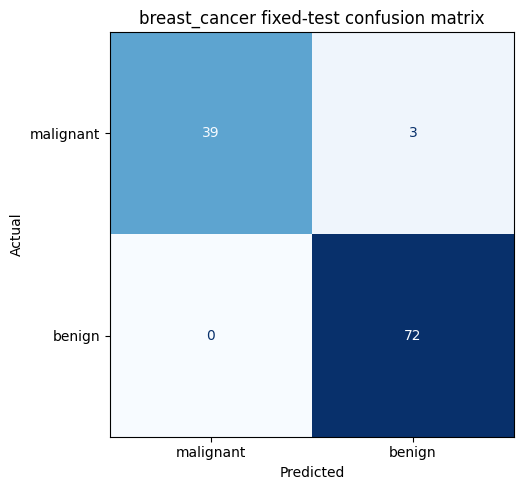

Malignant positive: TP= 39 FN= 3 FP= 0 TN= 72
Manual precision, recall, F1: 1.0 0.9285714285714286 0.962962962962963 ; report class: {'precision': 1.0, 'recall': 0.9285714285714286, 'f1-score': 0.9629629629629629, 'support': 42.0}


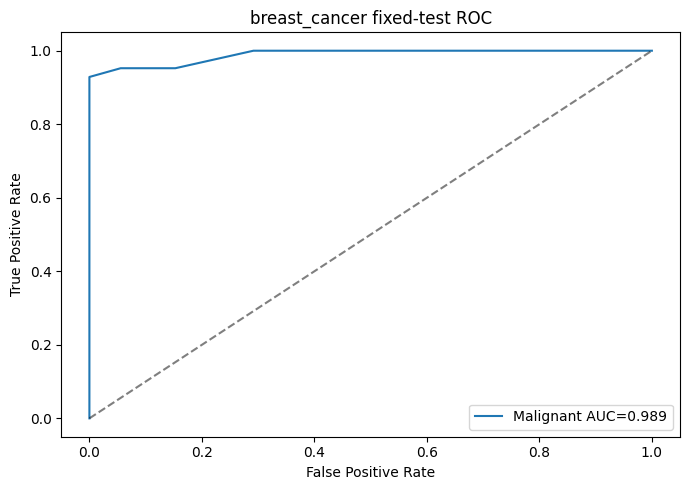

Actual misclassification: original row index 41 actual 0 predicted 1
Interpretation: Increasing a positive-class threshold generally reduces false positives but increases false negatives. Test metrics are descriptive; no retuning is done. Small validation splits and overlapping seeds limit inference.


In [9]:
algo=winner['algorithm'];rep=winner['representation'];param=winner['parameter'];model=fitted[(algo,rep,param)];test_x=prepared[42][rep][2];test_y=y_test
sc=scores(model,test_x,test_y,dataset);pred=model.predict(test_x);proba=model.predict_proba(test_x)
final=pd.DataFrame([dict(dataset=dataset,configuration_id=winner['configuration_id'],evaluation_seed=42,val_f1_mean=winner['val_f1_mean'],val_f1_std=winner['val_f1_std'],**{'test_'+k:v for k,v in sc.items()})]);display(final)
labels=list(model.classes_);names=list(bunch.target_names);report=classification_report(test_y,pred,labels=labels,target_names=names,zero_division=0,output_dict=True);display(pd.DataFrame(report).T)
cm=confusion_matrix(test_y,pred,labels=labels);fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay(cm,display_labels=names).plot(ax=ax,cmap='Blues',values_format='d',colorbar=False);ax.set_xlabel('Predicted');ax.set_ylabel('Actual');ax.set_title(dataset+' fixed-test confusion matrix');savefig(dataset+'_confusion_matrix.png')
if dataset=='breast_cancer':
 TP, FN, FP, TN=cm[0,0],cm[0,1],cm[1,0],cm[1,1];chosen=0
 print('Malignant positive: TP=',TP,'FN=',FN,'FP=',FP,'TN=',TN)
else:
 chosen=0;TP=cm[chosen,chosen];FN=cm[chosen,:].sum()-TP;FP=cm[:,chosen].sum()-TP;TN=cm.sum()-TP-FN-FP
 print('Wine class 0 one-vs-rest:',TP,FN,FP,TN)
manual_p=TP/(TP+FP) if TP+FP else np.nan;manual_r=TP/(TP+FN) if TP+FN else np.nan;manual_f=2*manual_p*manual_r/(manual_p+manual_r) if manual_p+manual_r else np.nan
print('Manual precision, recall, F1:',manual_p,manual_r,manual_f,'; report class:',report[names[chosen]])
fig,ax=plt.subplots(figsize=(7,5))
if dataset=='breast_cancer':
 fpr,tpr,_=roc_curve((test_y==0).astype(int),proba[:,labels.index(0)]);ax.plot(fpr,tpr,label=f'Malignant AUC={auc(fpr,tpr):.3f}')
else:
 for c in labels:
  fpr,tpr,_=roc_curve((test_y==c).astype(int),proba[:,labels.index(c)]);ax.plot(fpr,tpr,label=f'{names[c]} AUC={auc(fpr,tpr):.3f}')
ax.plot([0,1],[0,1],'k--',alpha=.5);ax.set_xlabel('False Positive Rate');ax.set_ylabel('True Positive Rate');ax.legend();ax.set_title(dataset+' fixed-test ROC');savefig(dataset+'_roc.png')
errors=np.flatnonzero(np.asarray(test_y)!=pred)
if len(errors):
 i=errors[0];print('Actual misclassification: original row index',test_x.index[i],'actual',test_y.iloc[i],'predicted',pred[i])
else:print('No test misclassifications. One error-free test does not prove perfect generalisation.')
if dataset=='wine':
 off=cm.copy();np.fill_diagonal(off,0)
 if off.max():r,c=np.unravel_index(off.argmax(),off.shape);print('Largest off-diagonal:',names[r],'misclassified as',names[c],off[r,c])
 else:print('No off-diagonal errors.')
print('Interpretation: Increasing a positive-class threshold generally reduces false positives but increases false negatives. Test metrics are descriptive; no retuning is done. Small validation splits and overlapping seeds limit inference.')
final.to_csv(ROOT/(dataset+'_classifier_test.csv'),index=False)

## 10. K-Means Clustering

,dataset,seed,representation,inertia,val_ari,val_silhouette,valid_silhouette
0,breast_cancer,42,unscaled,5.156538e+07,0.399462,0.638725,1
1,breast_cancer,42,scaled,7.918810e+03,0.451557,0.285448,1
2,breast_cancer,52,unscaled,4.919078e+07,0.612245,0.697473,1
3,breast_cancer,52,scaled,8.003001e+03,0.558609,0.375031,1
4,breast_cancer,62,unscaled,5.305649e+07,0.501339,0.695777,1
5,breast_cancer,62,scaled,7.922515e+03,0.733598,0.275781,1


,dataset,representation,inertia_mean,inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_seed_count
0,breast_cancer,scaled,7.948109e+03,4.757427e+01,0.581255,0.142378,0.312086,0.054725,3
1,breast_cancer,unscaled,5.127088e+07,1.949607e+06,0.504349,0.106423,0.677325,0.033440,3


Features selected using seed-42 training variance:
['worst area', 'mean area']
worst area    322165.921006
mean area     123948.496447
dtype: float64
Interpretation: The two projection features were selected using variance calculated only from seed-42 training data. No validation or test labels were used for feature selection. K-Means was still fitted using all original features.
Contingency unscaled


cluster_id,0,1
true_class,,
0,14,28
1,72,0


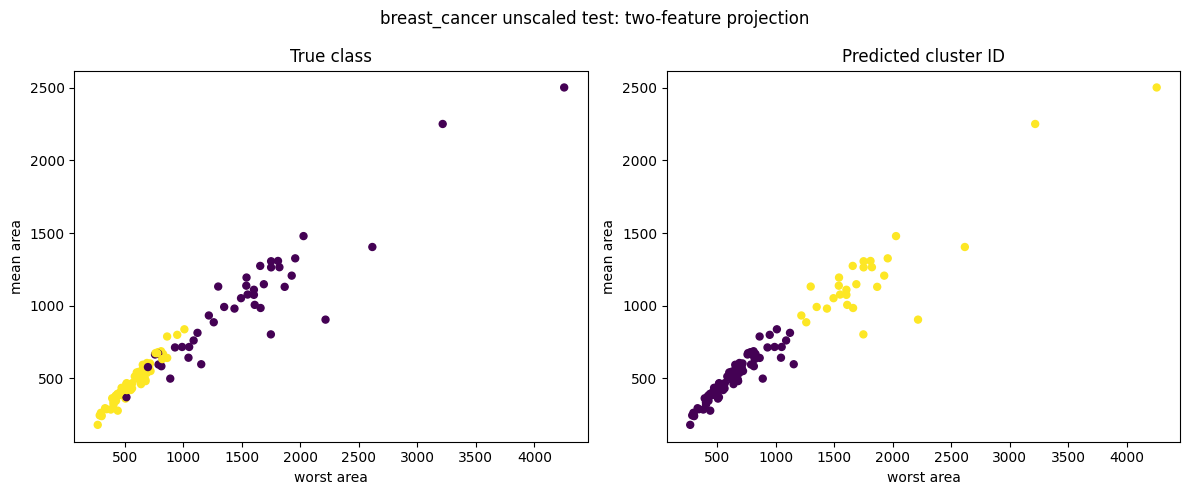

Contingency scaled


cluster_id,0,1
true_class,,
0,5,37
1,69,3


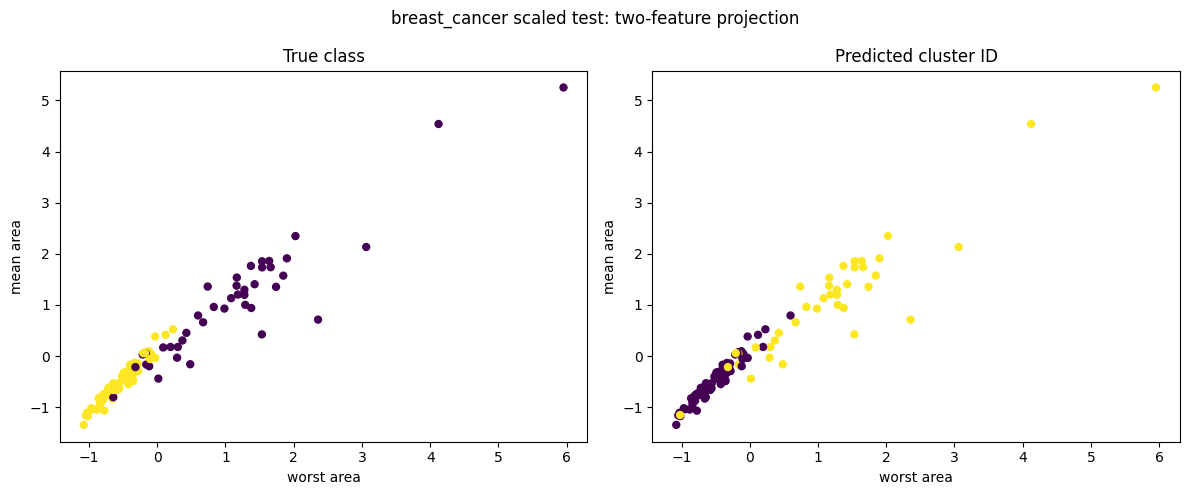

Selected features: ['worst area', 'mean area']
Training variances:
worst area    322165.921006
mean area     123948.496447
dtype: float64
Interpretation: Two visualization features were selected using variance from seed-42 training data only. Raw variance is affected by measurement units, so this selection is intended for visualization, not feature importance. K-Means still uses all original features.


,dataset,representation,seed,test_cluster_counts,test_ari,test_silhouette
0,breast_cancer,unscaled,42,"{0: 86, 1: 28}",0.558488,0.711999
1,breast_cancer,scaled,42,"{0: 74, 1: 40}",0.735381,0.325062


In [10]:
km_runs=[];km_models={};km_tests=[]
for seed in SEEDS:
 for rep in ['unscaled','scaled']:
  a,b,_=prepared[seed][rep];km=KMeans(n_clusters=2 if dataset=='breast_cancer' else 3,random_state=seed,n_init=10);km.fit(a)
  if seed==42:km_models[rep]=km
  clusters=km.predict(b);km_runs.append(dict(dataset=dataset,seed=seed,representation=rep,inertia=km.inertia_,val_ari=adjusted_rand_score(splits[seed]['y_val'],clusters),val_silhouette=sil(b,clusters),valid_silhouette=int(np.isfinite(sil(b,clusters)))))
km_df=pd.DataFrame(km_runs);display(km_df);assert len(km_df)==6
km_summary=km_df.groupby(['dataset','representation'],as_index=False).agg(inertia_mean=('inertia','mean'),inertia_std=('inertia','std'),val_ari_mean=('val_ari','mean'),val_ari_std=('val_ari','std'),val_silhouette_mean=('val_silhouette','mean'),val_silhouette_std=('val_silhouette','std'),valid_seed_count=('valid_silhouette','sum'));display(km_summary)

# Select two visualization features using seed-42 training data only.
# Rank features by their variance after training-fitted scaling.
train_unscaled = prepared[42]['unscaled'][0]
feature_variances = train_unscaled.var(axis=0, ddof=1)
chosen_features = feature_variances.nlargest(2).index.tolist()

print("Features selected using seed-42 training variance:")
print(chosen_features)
print(feature_variances.loc[chosen_features])

print(
    "Interpretation: The two projection features were selected "
    "using variance calculated only from seed-42 training data. "
    "No validation or test labels were used for feature selection. "
    "K-Means was still fitted using all original features."
)

for rep in ['unscaled','scaled']:
 xx=prepared[42][rep][2];cluster=km_models[rep].predict(xx);counts=pd.Series(cluster).value_counts().sort_index().to_dict();ari=adjusted_rand_score(y_test,cluster);ss=sil(xx,cluster)
 km_tests.append(dict(dataset=dataset,representation=rep,seed=42,test_cluster_counts=str(counts),test_ari=ari,test_silhouette=ss))
 contingency=pd.crosstab(pd.Series(y_test.to_numpy(),name='true_class'),pd.Series(cluster,name='cluster_id'));print('Contingency',rep);display(contingency)
 fig,axes=plt.subplots(1,2,figsize=(12,5))
 for ax,labels_,title in [(axes[0],y_test.to_numpy(),'True class'),(axes[1],cluster,'Predicted cluster ID')]:
  ax.scatter(xx[chosen_features[0]],xx[chosen_features[1]],c=labels_,cmap='viridis',s=25);ax.set_title(title);ax.set_xlabel(chosen_features[0]);ax.set_ylabel(chosen_features[1])
 fig.suptitle(dataset+' '+rep+' test: two-feature projection');savefig(dataset+'_clusters_'+rep+'.png')

# Select visualization features using seed-42 training data only.
# Use the two features with the largest raw training variance.
train_unscaled = prepared[42]['unscaled'][0]
feature_variances = train_unscaled.var(axis=0, ddof=1)
chosen_features = feature_variances.nlargest(2).index.tolist()

print("Selected features:", chosen_features)
print("Training variances:")
print(feature_variances.loc[chosen_features])

print(
    "Interpretation: Two visualization features were selected "
    "using variance from seed-42 training data only. "
    "Raw variance is affected by measurement units, so this "
    "selection is intended for visualization, not feature importance. "
    "K-Means still uses all original features."
)
km_test=pd.DataFrame(km_tests);display(km_test)
km_df.to_csv(ROOT/(dataset+'_kmeans_runs.csv'),index=False);km_summary.to_csv(ROOT/(dataset+'_kmeans_summary.csv'),index=False);km_test.to_csv(ROOT/(dataset+'_kmeans_test.csv'),index=False)